## **The Dropout Knob: How MUCH is Too Much?**

*Is the network actually learning, or just memorizing? We will turn the knob to find out.*

Before diving into technicalities, let us first define regularization. The Cambridge Dictionary defines it as

>*"the act of changing a situation or system so that it follows rules or is based on reason."*

Let us think about that. A rule stops a system from going wild.

In data science, the International Business Machines Corporation (IBM) describes it as

> *"a set of methods for reducing overfitting in machine learning models. Typically, regularization trades a marginal decrease in training accuracy for increased generalizability."*

Notice how these two definitions actually link? Both talk about setting rules to keep the system from chaos and help it learn.

Still not getting the hang of it?  Worry not! Let us put it this way:

> **Student A** is brilliant at memorizing what is on its past papers—word for word—perfect on those papers, BUT lost when the real exam is worded differently.

> **Student B** then learns the underlying ideas—slightly less perfect on past papers, but solid on the real exam.

Obviously, if we understand it, Regularization is the set of rules that pushes it to behave like **Student B**—learning the pattern and not the exact answers.

With regularization in place, let us dive deep into one of its techniques: “The Dropout Knob.”

### **What is a Dropout Knob?**

It is not really called a knob; I chose to call it that because it functions like one. We already knew that Dropout is one of Regularization’s techniques, but techniques to what?

It helps overcome overfitting in a neural network and also helps avoid relying on most of the neurons, which can lead to ‘memorizing’ the training data; in simpler terms, it avoids being like **Student A.**

However, before we proceed, do we know what overfitting and underfitting are?

> **Overfitting** is like **Student A**, it performs with high accuracy on training data (past papers) but poorly on unseen data because it memorizes instead of generalizing, which is what performs better on unseen data.

> **Underfitting:** it performs poorly on both training and testing data because it reduces neurons too much, so it fails to capture important patterns in the data.

Now that we have learned the basics, we are about to explore what dropout is in actual scenarios; let us compare it across knobs, and by knobs I mean comparing it with other switches.

Let us First look at an example where we apply no Drropouts at all compared to a generalized one, like student A and Student B!

### **Import Libraries**

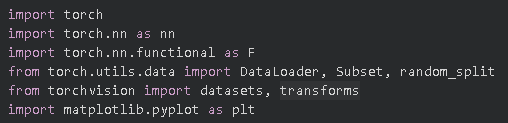

**No Dropout vs With Dropout**

These `dropout_p` values are what we call our knob on the neural network. We can adjust how much of the network is forced to "forget" during training. The value p is the setting on that knob: it represents the fraction of neurons we randomly switch off.

To see the effect, we need to train two separate models with everything kept identical (same data, same seed, same epochs), changing only the knob setting:

* Run A (No Dropout): We set p = 0.0, meaning the knob is off. This is our baseline (Student A).
* Run B (With Dropout): We set p = 0.5, meaning we randomly switch off 50% of the neurons in the dense layer. This is our regularized model (Student B).

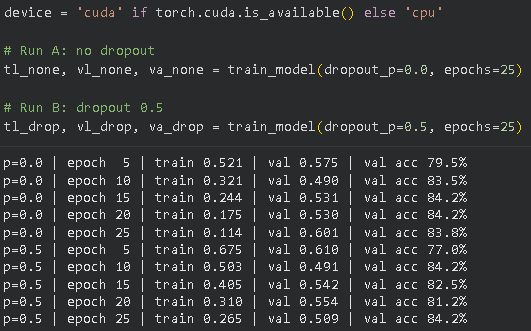

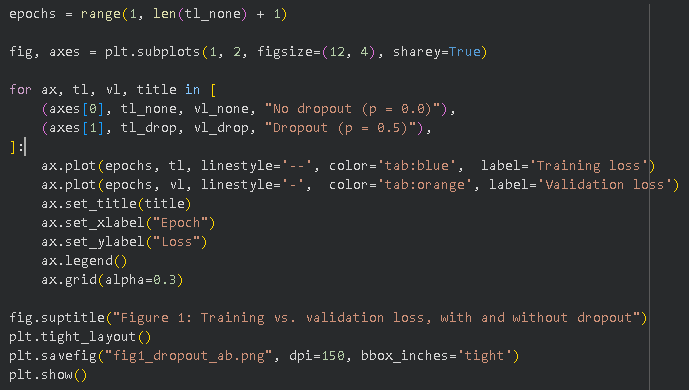

*Figure 1*

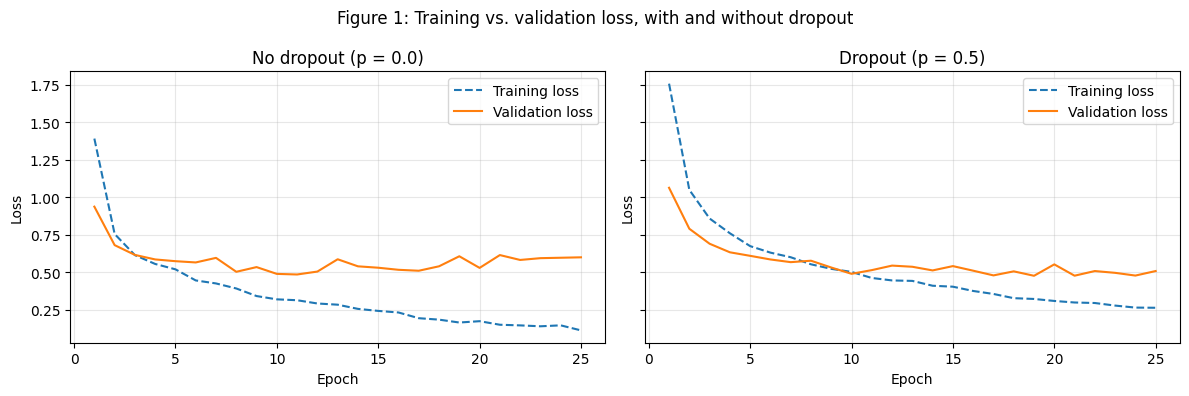

Here, we can observe that our `left panel (p = 0.0)` looks like **Student A**: the training loss (dashed line) drops toward zero, meaning the network is memorizing the training images perfectly. However, the validation loss (solid line) stops improving and starts rising after epoch 10. This is overfitting, just like **Student A** failing the real exam after memorizing past papers and not really learning.

Now look at the `right panel (p = 0.5)` that served as our **Student B** this time: the two lines are much closer together. The training loss stays higher because making the network forget (dropout) makes training harder. But the validation loss stays stable and low. This network is actually learning the underlying pattern—just like **Student B**.



### **The Knob**

Now, we are comparing different settings on the dropout knob to see how they affect overfitting and underfitting. We will sweep the value of p across four settings: 0.0, 0.2, 0.5, and 0.8.

The code below runs the same training loop for each setting and saves the results. (Notice that we keep the data, epochs, and seed identical—we only change p!)

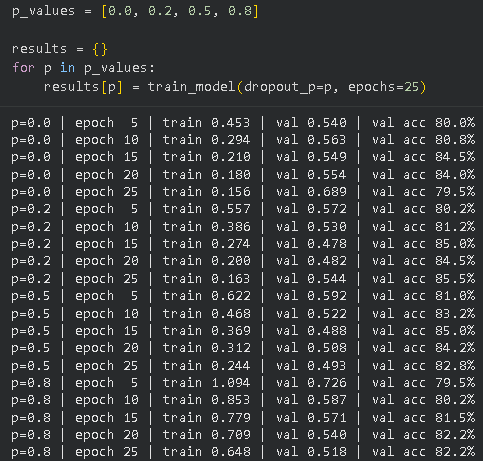

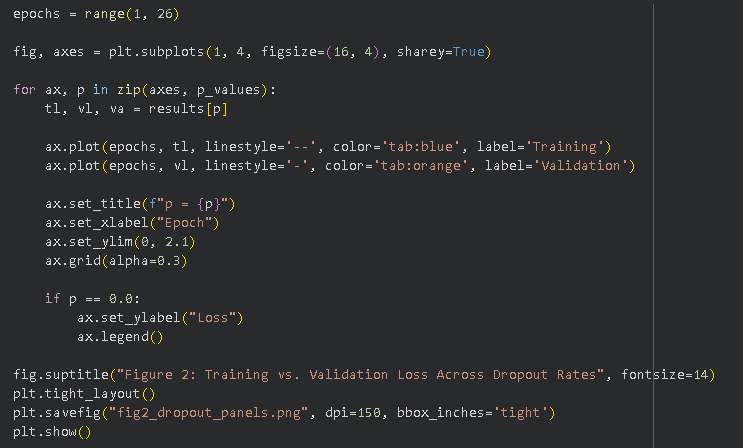

*Figure 2*


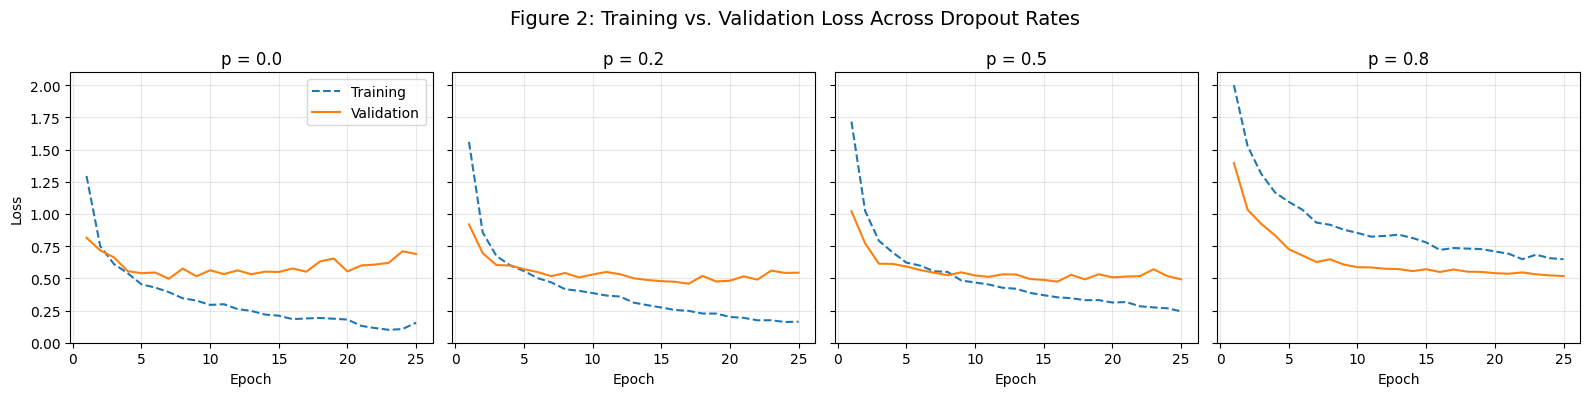

**Graph 1 (p=0.0):**

* Training loss dives toward zero while validation loss stalls/rises; we can observe that the gap indicates overfitting.
* The network is memorizing the training images perfectly, but it is failing to apply that knowledge to the validation images.

**Graph 2 (p=0.2):**

* The blue training line does not go as low as it did in Panel 1. The orange validation line stays mostly flat and does not creep up as much.
* A little dropout stopped the network from memorizing. It generalizes better.

**Graph 3 (p=0.5):**

* The blue and orange lines are closest together here. The training line stays higher, and the validation line stays lower.
* The network is forced to learn the true pattern because it cannot rely on any single neuron. It hasn't memorized, but it also has not given up.

**Graph 4 (p=0.8):**

* The orange validation line is actually lower than the blue training line for most of the graph. Both lines stay high.
* Because we switched off 80% of the neurons during training, the task was hard. However, during validation `(model.eval())`, dropout is turned off, and the full network is used, which is why validation loss looks better. However, both losses are high. The network is underfitting—it is too crippled to learn the pattern well.



Would you like to try it yourself? Click this [notebook](https://colab.research.google.com/drive/1yqNZf3_T-DF-sqdnaKRZChf4EZcY113K?usp=sharing) to open it directly.

### **Dropout and Weight Decay**

Talking about `Weight Decay`, it is also a regularization technique, but it addresses overfitting differently. GeeksforGeeks defines weight decay as a technique that

> *“penalizes large weights, encouraging a more balanced model.”*



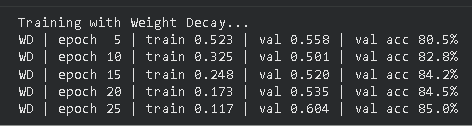

Let’s look at the validation loss for Weight Decay. It hits its lowest point at epoch 10  with 0.501, but by epoch 25, it climbed back to 0.604. Like the no-regularization model, the network starts to overfit toward the end of training. However, it achieved its best final validation accuracy of 85.0%. This proves that while weight decay did not eliminate overfitting, it kept the network from overfitting enough to score higher on unseen data.



*Figure 3*

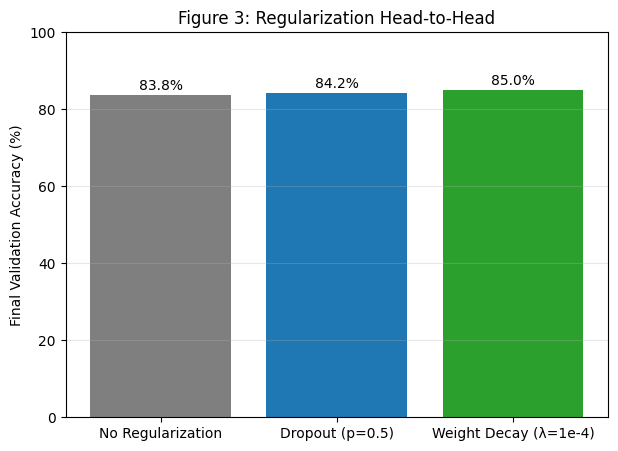

*Now, does this mean `Weight Decay` is actually better than `Dropout`?*

In Figure 3, weight decay narrowly beat dropout (85.0% vs 84.2%). 

BUT it does not necessarily mean it is better.

Here is the catch: on a tiny dataset of 2,000 images, 0.8% accuracy is literally just 3 images out of the 400 validation images. It is practically a tie. Look at how they got there. Weight decay keeps the weights small. Dropout, on the other hand, is a much more aggressive and powerful tool.

In this experiment, dropout did exactly what it was supposed to do: it prevented the network from memorizing (which we saw clearly in Figure 2). The fact that it tied with weight decay proves that dropout is also a strong regulariser. In real-world, deeper networks with millions of parameters, dropout is often the go-to method because it forces the network to learn redundant, robust features—not just small weights.

**How about you? How do you learn? Through understanding or memorizing?**



**REFERENCES**

Cambridge University Press & Assessment. (n.d.). Regularization. In the Cambridge dictionary. Retrieved November 20, 2026, from https://dictionary.cambridge.org/dictionary/english/regularization

GeeksforGeeks. (2025, December 19). Dropout regularization in deep learning. https://www.geeksforgeeks.org/deep-learning/dropout-regularization-in-deep-learning/

GeeksforGeeks. (2024, February 10). Dropout vs weight decay. https://www.geeksforgeeks.org/machine-learning/dropout-vs-weight-decay/

Salunke, M. (2024, December 4). Dropout regularization technique. Medium. https://medium.com/@mangeshsalunke1309/dropout-regularization-technique-a770fbcd9692


_AI Tool Usage Note: I used DeepSeek to help debug code and check the clarity of my explanations, and Grammarly to check my grammar and spelling. The experiment, the figures, and the analysis are entirely my own work._